In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('IKEA Gifting Dataset/Retail_Cleaned.csv', header=None, low_memory=False)
df.columns =['Invoice', 'stockCode', 'Description', 'Quantity','InvoiceDate', 'Price','Customer_ID', 'Country','SourceSheet']
df


,Invoice,stockCode,Description,Quantity,InvoiceDate,Price,Customer_ID,Country,SourceSheet
0,519822,21745,GAOLERS KEYS DECORATIVE GARDEN,2,2010-08-20 14:14:00.0000000,3.75,18106.0,United Kingdom,2010-2011
1,519822,21755,LOVE BUILDING BLOCK WORD,1,2010-08-20 14:14:00.0000000,5.95,18106.0,United Kingdom,2010-2011
2,519822,21770,OPEN CLOSED METAL SIGN,1,2010-08-20 14:14:00.0000000,4.95,18106.0,United Kingdom,2010-2011
3,519822,21777,RECIPE BOX WITH METAL HEART,2,2010-08-20 14:14:00.0000000,7.95,18106.0,United Kingdom,2010-2011
4,519822,21826,EIGHT PIECE DINOSAUR SET,4,2010-08-20 14:14:00.0000000,1.25,18106.0,United Kingdom,2010-2011
...,...,...,...,...,...,...,...,...,...
1033031,519822,21069,VINTAGE BILLBOARD TEA MUG,2,2010-08-20 14:14:00.0000000,1.25,18106.0,United Kingdom,2010-2011
1033032,519822,21080,SET/20 RED SPOTTY PAPER NAPKINS,2,2010-08-20 14:14:00.0000000,0.85,18106.0,United Kingdom,2010-2011
1033033,519822,21171,BATHROOM METAL SIGN,1,2010-08-20 14:14:00.0000000,1.45,18106.0,United Kingdom,2010-2011
1033034,519822,21524,DOORMAT SPOTTY HOME SWEET HOME,2,2010-08-20 14:14:00.0000000,7.49,18106.0,United Kingdom,2010-2011


In [3]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print(df.shape)
df.info()

(1033036, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1033036 entries, 0 to 1033035
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1033036 non-null  object        
 1   stockCode    1033036 non-null  object        
 2   Description  1028761 non-null  object        
 3   Quantity     1033036 non-null  int64         
 4   InvoiceDate  1033036 non-null  datetime64[ns]
 5   Price        1033036 non-null  float64       
 6   Customer_ID  797885 non-null   float64       
 7   Country      1033036 non-null  object        
 8   SourceSheet  1033036 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(5)
memory usage: 70.9+ MB


In [4]:
##FILTER THE DATA
num = len(df)

df = df[df["Customer_ID"].notna()]
print("After removing missing customers :", len(df))

df = df[~df["Invoice"].astype(str).str.startswith("C")]
print("After removing cancellations     :", len(df))

df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
print("After removing bad qty/price     :", len(df))

df["Revenue"] = df["Quantity"] * df["Price"]

print("Customers:", df["Customer_ID"].nunique())
print("Invoices :", df["Invoice"].nunique())
print("Total revenue:", round(df["Revenue"].sum(), 2))




After removing missing customers : 797885
After removing cancellations     : 779495
After removing bad qty/price     : 779407
Customers: 5878
Invoices : 36969
Total revenue: 17374804.25


In [5]:
### Calculate Recency, Frequency and Monetary
#### Recency: days since the customer’s last purchase (lower is better)
#### Frequency: number of different invoices (orders)
#### Monetary: total revenue from the customer

snapshot_date = df['InvoiceDate'].max().normalize() +pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)


rfm = df.groupby("Customer_ID").agg(
    Recency = ("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency = ("Invoice","nunique"),
    Monetary=("Revenue", "sum")
    
).round(2)

print(rfm.shape)
print(rfm.describe().round(2))
rfm.sort_values("Monetary", ascending=False).head(3)

Snapshot date: 2011-12-10 00:00:00
(5878, 3)
       Recency  Frequency   Monetary
count  5878.00    5878.00    5878.00
mean    200.87       6.29    2955.90
std     209.35      13.01   14440.85
min       0.00       1.00       2.95
25%      25.00       1.00     342.28
50%      95.00       3.00     867.74
75%     379.00       7.00    2248.30
max     738.00     398.00  580987.04


,Recency,Frequency,Monetary
Customer_ID,,,
18102.0,0,145,580987.04
14646.0,1,151,528602.52
14156.0,9,156,313437.62


In [6]:
##SCORE CUSTOMER AND ASSIGN BUSINESS SEGMENTS
rfm['R_Score'] = pd.qcut(rfm['Recency'],5,labels=[5,4,3,2,1]).astype(int)
rfm['F_Score']=pd.qcut(rfm['Frequency'].rank(method='first'),5,labels=[1,2,3,4,5]).astype(int)
rfm['M_Score']=pd.qcut(rfm['Monetary'],5,labels=[1,2,3,4,5]).astype(int)

def segment_customer(row):
    if row['R_Score'] >= 4 and row['F_Score']>=4 and row['M_Score'] >=4:
        return 'Champions'
    elif row['R_Score'] >=3 and row['F_Score'] >=3:
        return 'Loyal'
    elif row['R_Score']<=2 and row['F_Score']>=3:
        return 'At Risk'
    elif row['R_Score']>=4  and row['F_Score']<=2:
        return 'New'
    elif row['R_Score'] ==3 and row['F_Score']<=2:
        return 'Need Attention'
    else:
        return "Lost"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)
rfm["IsChurned"]=rfm['Recency'] >90

In [7]:
print(rfm["Segment"].value_counts())
print(order)

Segment
Lost              1522
Loyal             1415
Champions         1291
At Risk            821
New                441
Need Attention     388
Name: count, dtype: int64


NameError: name 'order' is not defined

In [8]:
## chart the segmnet
import matplotlib.pyplot as plt

order = ["Champions", "Loyal", "New", "Need Attention", "At Risk", "Lost"]

print(rfm["Segment"].value_counts().reindex(order))

plt.figure(figsize=(9, 5))
bars = plt.bar(counts.index, counts.values, color="#0058A3")

for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 15,
             int(bar.get_height()), ha="center", fontsize=10)

plt.title("Customers by RFM Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Segment
Champions         1291
Loyal             1415
New                441
Need Attention     388
At Risk            821
Lost              1522
Name: count, dtype: int64


NameError: name 'counts' is not defined

<Figure size 900x500 with 0 Axes>

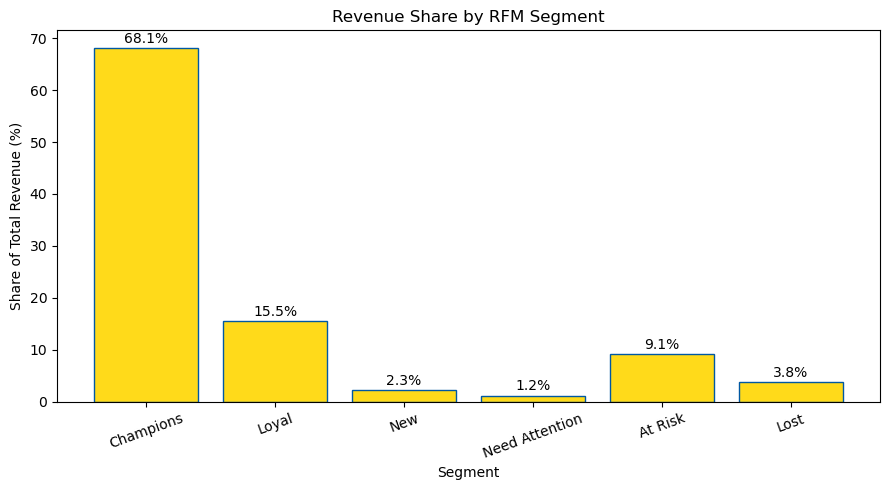

In [9]:
## Chart revenue share by segment
rev = rfm.groupby("Segment")["Monetary"].sum().reindex(order)
rev_pct = (rev / rev.sum() * 100).round(1)

plt.figure(figsize=(9, 5))
bars = plt.bar(rev_pct.index, rev_pct.values, color="#FFDA1A", edgecolor="#0058A3")

for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
             f"{bar.get_height()}%", ha="center", fontsize=10)

plt.title("Revenue Share by RFM Segment")
plt.xlabel("Segment")
plt.ylabel("Share of Total Revenue (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [10]:
### MERGE RFM RESULT BACK ONTO TRANSACTION AND EXPORT
df = df[(df['Customer_ID'].notna()) & (df['Quantity']>0) & (df['Price']>0)].copy()   
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M').dt.to_timestamp()
df['Revenue'] = df['Quantity'] * df['Price']

rfm_cols = rfm.reset_index()[['Customer_ID', 'Recency', 'Frequency', 'Monetary',
                              'R_Score', 'F_Score', 'M_Score', 'Segment', 'IsChurned']]

df_final = df.merge(rfm_cols, on='Customer_ID', how='left')

print(df_final.shape)
print("Rows without a segment:", df_final['Segment'].isna().sum())
print("Total revenue:", round(df_final['Revenue'].sum(), 2))



(779407, 19)
Rows without a segment: 0
Total revenue: 17374804.25


In [11]:
df_final.to_excel('EcommerceDashboardData.xlsx', index=False)